# Cross-correlation functions

## Configuration

### Import libraries & define helper functions

In [3]:
from pathlib import Path
import sys
import tomllib

from datautils.data import read
from datautils.query import CatalogueQuery
from datautils.time import TIME_PRECISION
import matplotlib.pyplot as plt
import matplotlib.style as mplstyle
import numpy as np
import pandas as pd
from scipy.signal import correlate

sys.path.insert(0, str(Path.cwd() / "src"))
import master, plotting

mplstyle.use("fast")


# def format_channel_text(
#     channel: int,
#     pulse_start: float,
#     pulse_end: float,
#     stwin: float,
#     ltwin: float,
#     threshold: float,
#     distance: float,
# ) -> str:
#     return (
#         "\n\n[[events.sensors.channels]]"
#         f"\nchannel = {channel}"
#         f"\npulse_start = {pulse_start}"
#         f"\npulse_end = {pulse_end}"
#         f"\nstwin = {stwin}"
#         f"\nltwin = {ltwin}"
#         f"\nthreshold = {threshold}"
#         f"\ndistance = {distance}"
#     )


# def format_event_text(event_name, event_site, event_start, event_stop) -> str:
#     return (
#         "\n[[events]]"
#         f'\nname = "{event_name}"'
#         f'\nsite = "{event_site}"'
#         f'\nstart = "{event_start}"'
#         f'\nend = "{event_stop}"'
#     )


# def format_sensor_text(
#     sensor_name,
#     filter_type,
#     filter_freq,
#     taper,
#     channels: list,
#     pulse_start: list,
#     pulse_end: list,
#     stwin: list,
#     ltwin: list,
#     threshold: list,
#     distance: list,
# ) -> str:
#     sensor_text = (
#         "\n[[events.sensors]]"
#         f'\nname = "{sensor_name}"'
#         f'\nfilter = "{filter_type}"'
#         f"\nfreq = {filter_freq}"
#         f"\ntaper = {taper}"
#     )
#     channel_text = "".join(
#         [
#             format_channel_text(
#                 channel=c,
#                 pulse_start=ps,
#                 pulse_end=pe,
#                 stwin=st,
#                 ltwin=lt,
#                 threshold=th,
#                 distance=d,
#             )
#             for c, ps, pe, st, lt, th, d in zip(
#                 channels, pulse_start, pulse_end, stwin, ltwin, threshold, distance
#             )
#         ]
#     )
#     return sensor_text + channel_text

### Set paths to data and logs

In [5]:
EVENT_LOG_PATH = Path("data/logs/events.csv")
SENSORS_PATH = Path("src/config/data.toml")
SAVEPATH = Path("data/results/")

### Select event

Set the `event_name` variable to the name of the event you want to work with. Possible selections are (all times UTC):

| Event | Start | Stop | Status |
|-------|-------|------| ------ |
| `Z01-A` | 2023-06-19T19:20 | 2023-06-19T21:10 |  |
| `Z01-B` | 2023-06-19T22:25 | 2023-06-19T23:00 |  |
| `Z01-C` | 2023-06-20T10:35 | 2023-06-20T10:50 |  |
| `Z01-D` | 2023-06-20T13:15 | 2023-06-20T15:20 |  |
| `A12-A` | 2023-07-02T17:00 | 2023-07-02T18:20 |  |
| `A12-B` | 2023-07-02T19:50 | 2023-07-02T21:35 |  |
| `A08` | 2023-07-06T15:15 | 2023-07-06T18:20 | ✅ |
| `A10-A` | 2023-07-08T19:00 | 2023-07-08T20:40 | ✅ |
| `A10-B` | 2023-07-09T10:00 | 2023-07-09T11:30 | ✅ |
| `A03` | 2023-07-12T19:00 | 2023-07-12T21:50 | ✅ |
| `A14` | 2023-07-21T20:00 | 2023-07-21T23:50 |  |
| `A11` | 2023-07-23T20:40 | 2023-07-24T01:20 |  |
| `A02` | 2023-07-31T19:00 | 2023-07-31T22:20 |  |
| `A15` | 2023-08-01T20:15 | 2023-08-01T22:50 |  |
| `A13` | 2023-08-03T14:40 | 2023-08-03T17:40 |  |
| `A01` | 2023-08-04T15:20 | 2023-08-04T18:25 |  |
| `A07` | 2023-08-05T21:00 | 2023-08-05T23:55 |  |
| `A04` | 2023-08-07T10:55 | 2023-08-07T13:45 |  |

In [6]:
event_name = "A03"
event_data = pd.read_csv(EVENT_LOG_PATH).set_index("Event").loc[event_name]
savedir = SAVEPATH / f"{event_name}_{event_data.Start[0:10]}"
# savedir.mkdir(exist_ok=True, parents=True)
print(event_data)

Start    2023-07-12T19:00:00
Stop     2023-07-12T21:50:00
Site                     A03
Lat                 41.10963
Lon                 -71.1472
Name: A03, dtype: object


### Sensors

In [57]:
# Filter type
filter_type = "bandpass"
# Filter cutoff freq(s) [Hz]
# filter_freq = 10.0
freqmin = 20.0
freqmax = 100.0
# Taper [s]
taper = 5.0
# Pulse Start [ms]
pulse_start = 500
# Pulse End [ms]
pulse_end = 500

with open(SENSORS_PATH, "rb") as f:
    sensor_info = tomllib.load(f)["data"]["sensors"]

#### Select Sensor & Channels

Set the `sensor_name` to one of the following and specify the channels you want to work with. Possible selections are:

| Sensor | Channels |
| --- | --- |
| Geosled (`SHRU921_Tetra`) | 0, 1, 2, 3 |
| VLA 1 (`SHRU905_VLA1`) | 0, 1, 2, 3 |
| VLA 2 (`SHRU920_VLA2`) | 0, 1, 2, 3 |

In [58]:
sensors = ["SHRU921_Tetra", "SHRU905_VLA1", "SHRU920_VLA2"]
channels = [0, 1, 2, 3]

#### Load Data

In [59]:
catalogue_paths = [master.get_catalogue(sensor_info, sn) for sn in sensors]

df_times = pd.read_csv(Path("data/results/A03_2023-07-12/metrics_SHRU921_Tetra.csv"))["time_init"]

time_start = [np.datetime64(t, TIME_PRECISION) for t in df_times]
time_end = [time_start + np.timedelta64(3000, "ms") for time_start in time_start]

time_start[0], time_end[0]


inv = []
i = 0
for i, (t0, t1) in enumerate(zip(time_start, time_end)):
    
    detection = {
        "index": i,
        "time_start": t0,
        "time_end": t1,
    }

    ds_list = []
    for j, path in enumerate(catalogue_paths):
        cq = CatalogueQuery(
            catalogue=path,
            destination=None,
            time_start=np.datetime64(t0, TIME_PRECISION),
            time_end=np.datetime64(t1, TIME_PRECISION),
            channels=channels,
        )
        ds = read(cq)
        if filter_type is not None:
            ds = ds.filter(filt_type=filter_type, freqmin=freqmin, freqmax=freqmax)
            ds = ds.decimate(20)
        
        ds_list.append(ds)
    
    num_samples = min([len(ds) for ds in ds_list])
    for j, ds in enumerate(ds_list):
        detection[f"stream{j+1}"] = ds[:num_samples]

    inv.append(detection)

    i += 1
    if i == 5:
        break

inv[0]

/var/folders/nj/vwkt9bx54ts200_1q_7bh0140000gn/T/ipykernel_51599/145912000.py:5: DeprecationWarning: parsing timezone aware datetimes is deprecated; this will raise an error in the future
  time_start = [np.datetime64(t, TIME_PRECISION) for t in df_times]


[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU921_Tetra/07121850.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU905_VLA1/07121732.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU920_VLA2/07121719.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU921_Tetra/07121850.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU905_VLA1/07121732.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU920_VLA2/07121719.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU921_Tetra/07121850.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU905_VLA1/07121732.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU920_VLA2/07121719.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU921_Tetra/07121850.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU905_VLA1/07121732.D23')]
[PosixPath('/Volumes/T7_Shield/RODEOII/data/acoustic/SHRU920_VLA2/07121719.D23')]
[PosixPath('

{'index': 0,
 'time_start': numpy.datetime64('2023-07-12T19:06:48.629948'),
 'time_end': numpy.datetime64('2023-07-12T19:06:51.629948'),
 'stream1': DataStream(waveform=[[   -2620.66458424    -3770.00738263    -2853.88350193    -3535.68144736]
  [    2438.9683174      6150.20402695     4403.42807055     5246.30785153]
  [   45451.89432932   119672.74932435    61212.73801482    91050.49776292]
  ...
  [ -497558.04093462  -593733.57821852  -432714.61300995  -526098.73473296]
  [-1271746.69265342 -1380987.04329327 -1162795.30493005 -1277963.15538153]
  [-1600705.73627128 -1711513.59086237 -1477790.05648978 -1600526.44285062]], channels=[0, 1, 2, 3], num_channels=4, num_samples=2930, time_init=2023-07-12T19:06:48.629969, time_end=2023-07-12T19:06:51.629981, sampling_rate=976.5625013427555), units=uPa,
 'stream2': DataStream(waveform=[[-7.14179771e+02 -2.50133629e+03  9.82403785e+02  8.27993988e+02]
  [ 2.08438949e+03  7.95242304e+03  3.64570247e+03  6.16517421e+03]
  [ 4.07361516e+04  1.40

976.5625013427555
2930 2930 2930


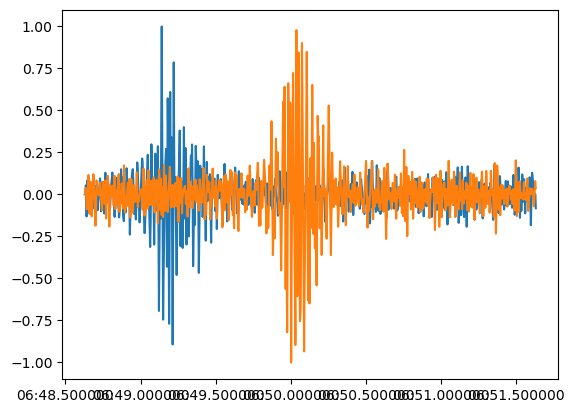

In [60]:
# All data streams have to have the same number of samples, `num_samples`.
# This is required for the cross-correlation calculation.

detection0 = inv[0]
ds1 = detection0["stream1"]
ds2 = detection0["stream2"]
ds3 = detection0["stream3"]

print(ds1.stats.sampling_rate)

t1 = ds1.time_vector
t2 = ds2.time_vector
t3 = ds3.time_vector
sig1 = ds1.waveform[:, 0] / np.max(np.abs(ds1.waveform[:, 0]))
sig2 = ds2.waveform[:, 0] / np.max(np.abs(ds2.waveform[:, 0]))
sig3 = ds3.waveform[:, 0] / np.max(np.abs(ds3.waveform[:, 0]))
print(len(sig1), len(sig2), len(sig3))

plt.plot(t1, sig1)
plt.plot(t2, sig2)
# plt.plot(t3, sig3)

Cross correlation functions are calculated for each pair of channels. The data is loaded and preprocessed for each channel pair.

In [77]:
def cross_correlation(sig1, sig2, step_size=1, window_size=None):
    # Length of the signals
    signal_length = len(sig1)

    if window_size is None:
        window_size = signal_length

    # Number of windows
    num_windows = (signal_length - window_size) // step_size + 1

    # Pre-allocate the cross-correlation results as a numpy matrix
    cross_corr_length = 2 * window_size - 1
    ccf = np.zeros((num_windows, cross_corr_length))

    for i, start in enumerate(range(0, signal_length - window_size + 1, step_size)):
        segment1 = sig1[start : start + window_size]
        segment2 = sig2[start : start + window_size]
        ccf[i] = np.correlate(segment1, segment2, mode="full")
    return ccf


# Compute cross-correlation with sliding window
window_size = len(sig1)
step_size = 1
print(f"Window duration is {window_size / ds1.stats.sampling_rate} s")
print(f"Step size is {step_size / ds1.stats.sampling_rate} s")

sig1_ch = 0
sig1_depths = [16.2, 17.7, 21.3, 22.8]
sig1_depth_factor = 1

# CCF Dimensions:
# 0: Detection
# 1: Channel
# 2: Window

ccfs = np.zeros((len(inv), 4, 2 * window_size - 1))
for i, detection in enumerate(inv):
    keys = [k for k in detection.keys() if "stream" in k]
    detection_waveforms = [ds for ds in [detection[k] for k in keys]]
    print(len(detection_waveforms))
    # for j, ds in enumerate(detection_waveforms):
    #     # TODO: Fix the indexing/dimensions for the channels
    #     sig1 = ds.waveform[:, sig1_ch] / np.max(np.abs(ds.waveform[:, sig1_ch]))
    #     sig2 = ds.waveform[:, 0] / np.max(np.abs(ds.waveform[:, 0]))
    #     print(sig1.shape, sig2.shape)
    #     ccfs[i, j] = cross_correlation(sig1, sig2, step_size, window_size)


# ccfs = []
# for ch in range(4):
#     sig1 = ds1.waveform[:, sig1_ch] / np.max(np.abs(ds1.waveform[:, sig1_ch]))
#     sig2 = ds2.waveform[:, ch] / np.max(np.abs(ds2.waveform[:, ch]))
#     ccfs.append(cross_correlation(sig1, sig2, step_size, window_size))

# ccf_sums = [ccf.mean(axis=0) / np.max(np.abs(ccf.mean(axis=0))) for ccf in ccfs]


Window duration is 3.0003199958746154 s
Step size is 0.0010239999985920188 s
3
3
3
3
3


In [74]:
det_ind = 1
ccf = ccfs[det_ind, :]
ccf.shape

# [plt.plot(ccf + sig1_depths[i] * sig1_depth_factor, "k") for i, ccf in enumerate(ccf_sums)]
# plt.plot(ccf[])
# plt.gca().invert_yaxis()
# plt.ylim(25, 10)
# plt.show()

(3, 5859)

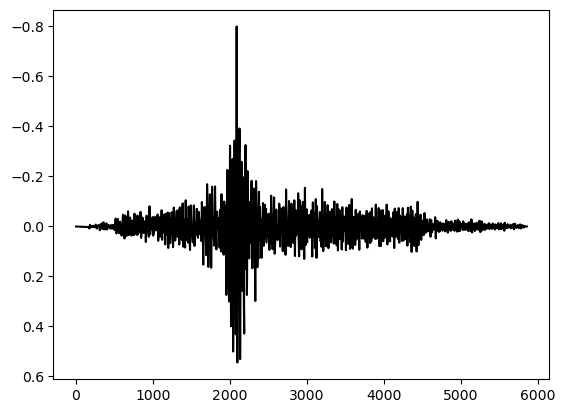

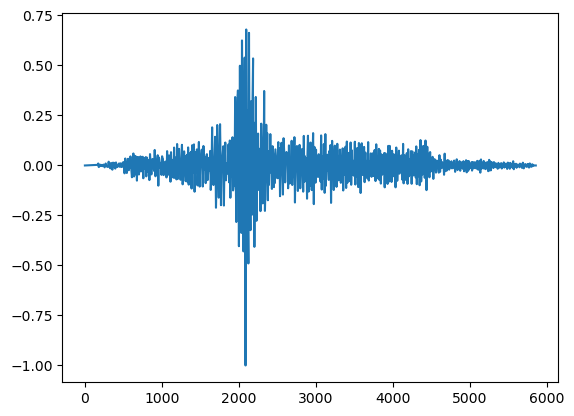

In [64]:
ccf = ccfs[0]
row_max = np.max(np.abs(ccfs[0]), axis=1, keepdims=True)
row_max[row_max == 0] = 1
ccf_norm = ccf / row_max

scale = 0.8
[plt.plot(scale * ccf + 2 * i, "k") for i, ccf in enumerate(ccf_norm)]
plt.gca().invert_yaxis()
# plt.ylim(100, -1)
plt.show()

plt.plot(ccf_norm.mean(axis=0))
plt.show()
